# Øvelsescase: KaffeCaféen, løsningsforslag

Casen var den afsluttende case-eksamen på et tidligere introkursus i Python. Den samler det, du har øvet i notebook 1 og 2, i fem opgaver. Til eksamen havde man 30 minutter og måtte bruge sine notebooks og noter, men ikke søgemaskiner eller AI-værktøjer. Prøv gerne casen på samme vilkår. Dette er løsningsforslaget.

## Før du starter: hent data

Du skal bruge filen `kaffecafeen.xlsx`. Der er to måder at få adgang til den:

**Mulighed A (upload):** Hent filen fra mappen [data](https://github.com/aaubs/AQM-2026/tree/main/python-refresher/da/data) i kursets GitHub-repo. Åbn fil-panelet i venstre side af Colab (mappe-ikonet), klik på upload-ikonet og vælg `kaffecafeen.xlsx`. Filen kan derefter indlæses med filnavnet `"kaffecafeen.xlsx"`.

**Mulighed B (link):** Indlæs filen direkte fra internettet med adressen i variablen `DATA_URL` (se opsætningscellen herunder). Så behøver du ikke uploade noget.

Begge måder giver de samme data. Vælg den, du er mest tryg ved.

## Når du er færdig

1. Kør hele notebooken forfra: menuen **Runtime > Run all** (Kørselstid > Kør alle).
2. Tjek at alle celler viser output uden fejl.

## Casen

Du er netop blevet ansat som administrativ medarbejder i **KaffeCaféen**, en lille cafékæde med fire filialer i Nordjylland. Din leder har sendt dig et udtræk fra kassesystemet for juni og juli 2026. Hver række i filen er én **varelinje**: ét produkt solgt i et vist antal. Køber en kunde fx en latte og en kanelsnegl, giver det to rækker.

Kolonnerne er: `SalgsId`, `Dato`, `Filial`, `Produkt`, `Antal` og `StykPris` (pris pr. styk i kr.).

Din leder har bedt dig om at skabe overblik over salget. Det gør du i de fem opgaver herunder.

In [1]:
# Adressen på datafilen (bruges i Mulighed B, kør cellen før indlæsning af data):
DATA_URL = "https://raw.githubusercontent.com/aaubs/AQM-2026/main/python-refresher/da/data/kaffecafeen.xlsx"

## Opgave 1: Indlæs og inspicér data

Pandas er ikke importeret i opsætningscellen. Det er en del af opgaven.

Skriv kode der:
1. importerer pandas med det sædvanlige alias
2. indlæser `kaffecafeen.xlsx` i en DataFrame med navnet `df` (brug Mulighed A eller B)
3. viser de første 5 rækker af `df`
4. viser hvor mange rækker og kolonner `df` har

In [2]:
# === OPGAVE 1: Løsning ===

# 1. Importér pandas med alias pd
import pandas as pd


In [3]:
# 2. Indlæs kaffecafeen.xlsx i en DataFrame med navnet df
df = pd.read_excel(DATA_URL)

# Kan også skrives (Mulighed A, kræver upload): df = pd.read_excel("kaffecafeen.xlsx")

In [4]:
# 3. Vis de første 5 rækker
df.head()

,SalgsId,Dato,Filial,Produkt,Antal,StykPris
0,1065,2026-06-01,Nørresundby,Latte,3,42
1,1165,2026-06-01,Aalborg C,Kaffe,4,30
2,1177,2026-06-01,Aalborg Øst,Latte,1,42
3,1203,2026-06-01,Aalborg Øst,Kaffe,2,30
4,1285,2026-06-01,Hjørring,Latte,2,42


In [5]:
# 4. Vis antal rækker og kolonner (shape)
df.shape
# df.head() og df.shape kan også stå som sidste linje i hver sin celle uden print

(300, 6)

In [6]:
# SIKKERHEDSNET: Kør denne celle, uanset hvordan opgave 1 gik.
# Den indlæser data korrekt, så du kan løse opgave 2-5 selvom opgave 1 drillede.
import pandas as pd
df = pd.read_excel(DATA_URL)
print("Data er klar:", df.shape)

Data er klar: (300, 6)


## Opgave 2: Beregnet kolonne

Din leder vil kunne se, hvad hver varelinje har indbragt.

Skriv kode der:
1. opretter en ny kolonne i `df` med navnet `Omsætning`, beregnet som `Antal` gange `StykPris`
2. viser de første 5 rækker af `df`, så man kan se den nye kolonne

In [7]:
# === OPGAVE 2: Løsning ===

# 1. Opret kolonnen Omsætning = Antal * StykPris
df["Omsætning"] = df["Antal"] * df["StykPris"]


In [8]:
# 2. Vis de første 5 rækker af df
df.head()

,SalgsId,Dato,Filial,Produkt,Antal,StykPris,Omsætning
0,1065,2026-06-01,Nørresundby,Latte,3,42,126
1,1165,2026-06-01,Aalborg C,Kaffe,4,30,120
2,1177,2026-06-01,Aalborg Øst,Latte,1,42,42
3,1203,2026-06-01,Aalborg Øst,Kaffe,2,30,60
4,1285,2026-06-01,Hjørring,Latte,2,42,84


## Opgave 3: Opslag

Din leder ringer og spørger til én bestemt varelinje: den med **SalgsId 1088**.

Skriv kode der viser rækken med SalgsId 1088, så man kan aflæse `Produkt` og `Omsætning`.

*Tip: Data er ikke sorteret efter SalgsId, så du skal bruge kode, ikke scrolle.*

In [9]:
# === OPGAVE 3: Løsning ===

# Vis rækken hvor SalgsId er 1088
print(df[df["SalgsId"] == 1088])
# Kan også skrives: df.loc[df["SalgsId"] == 1088]
# Aflæsning: Produkt = Te, Omsætning = 56 kr.


     SalgsId       Dato       Filial Produkt  Antal  StykPris  Omsætning
220     1088 2026-07-16  Aalborg Øst      Te      2        28         56


## Opgave 4: Filtrér og beregn

Din leder vil vide, hvordan filialen i **Hjørring** klarer sig.

Skriv kode der:
1. udvælger de rækker i `df`, hvor `Filial` er `"Hjørring"`
2. beregner og viser **summen** af `Omsætning` for disse rækker
3. beregner og viser **gennemsnittet** af `Omsætning` for disse rækker

In [10]:
# === OPGAVE 4: Løsning ===

# 1. Udvælg rækkerne hvor Filial er "Hjørring"
hjoerring = df[df["Filial"] == "Hjørring"]

In [11]:
# 2. Vis summen af Omsætning for Hjørring
print(hjoerring["Omsætning"].sum())

5569


In [12]:
# 3. Vis gennemsnittet af Omsætning for Hjørring
print(hjoerring["Omsætning"].mean())
# Resultat: sum = 5569, gennemsnit = 94.39 (ca.)
# Filtrering og beregning kan også skrives i én linje, fx df[df["Filial"] == "Hjørring"]["Omsætning"].sum()

94.38983050847457


## Opgave 5: Visualisering

Til et møde vil din leder have et billede af, hvordan varelinjernes størrelse fordeler sig.

Færdiggør koden herunder, så den viser et **histogram** over kolonnen `Omsætning` med 8 intervaller (bins). Diagrammet skal have tekst på begge akser og en overskrift, så det kan forstås uden forklaring.

In [13]:
# Importér matplotlib.pyplot med det sædvanlige alias plt
import matplotlib.pyplot as plt

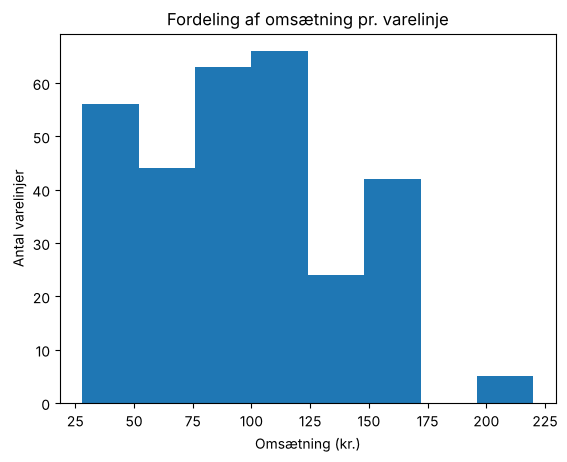

In [14]:
# === OPGAVE 5: Løsning ===

plt.hist(df["Omsætning"], bins=8)
plt.xlabel("Omsætning (kr.)")
plt.ylabel("Antal varelinjer")
plt.title("Fordeling af omsætning pr. varelinje")
plt.show()
# Andre aksetekster og overskrifter er lige så gode, så længe alle tre er udfyldt
# og der plottes df["Omsætning"] med bins=8

---

**Til sidst:** Kør Runtime > Run all, og tjek at alle celler viser output uden fejl.